# Week 5 - Transfer Learning

**Name:** Muhammad Luqman Khan 

**Subject:** Introduction to Applied AI

**Project:** Project 2: Deep Learning Applications

In [1]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cuda
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


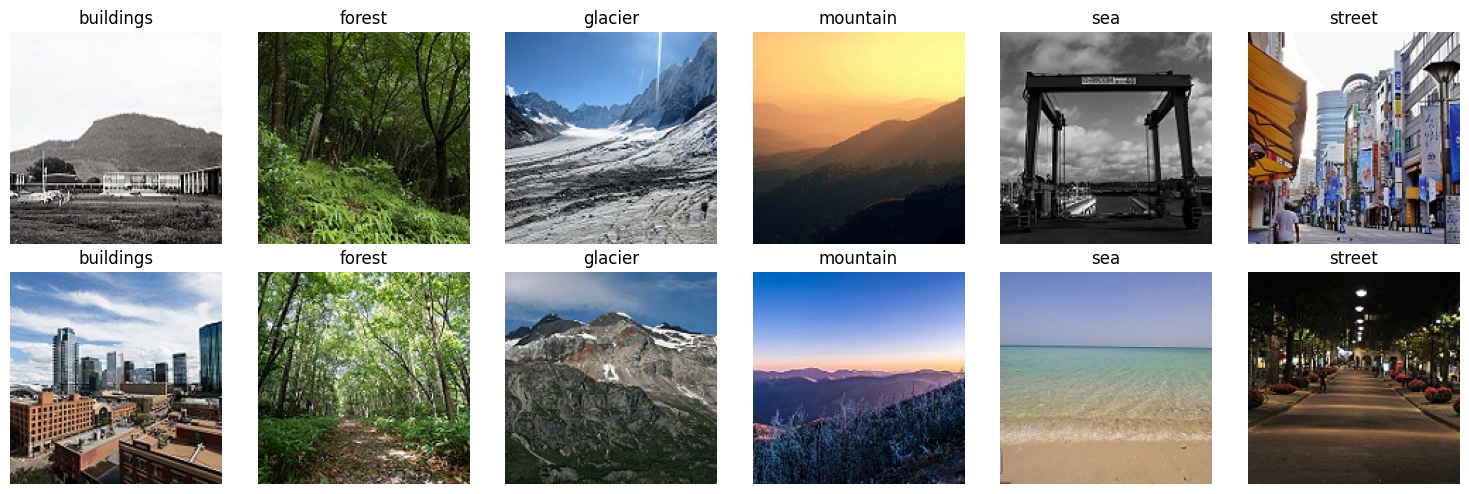

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [2]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

# Part 1: The Data, and an Image as Numbers

## GPU and dataset
The device is **`cuda` (Tesla T4)**, so all training runs on the GPU. The dataset has **6 scene classes** and is well balanced (2,191 to 2,512 training images per class), so accuracy is a fair metric.

| Class | Train | Test |
|---|---|---|
| buildings | 2,191 | 437 |
| forest | 2,271 | 474 |
| glacier | 2,404 | 553 |
| mountain | 2,512 | 525 |
| sea | 2,274 | 510 |
| street | 2,382 | 501 |
| **Total** | **14,034** | **3,000** |

## An image as numbers
- **Shape (H, W, C):** **(150, 150, 3)**: 150 pixels high, 150 wide, 3 colour channels (R, G, B)
- **Data type:** **uint8** (whole numbers)
- **Value range:** **0 to 255** (0 = no light, 255 = full intensity)
- **Values per image:** 150 × 150 × 3 = **67,500**
- **Top-left 3×3 of the red channel:** `[[8, 6, 3], [6, 5, 4], [5, 5, 5]]`. All values are near 0 because that corner of the night-time street photo is almost black.

## Which classes look most similar? (prediction made before training)
By eye, **glacier and mountain** look most alike: both show rocky peaks, snow and sky, and the glacier photo in my grid contains a snow-covered rocky mountain. **Buildings and street** are a second similar pair, since both show city structures.

**Prediction:** the model will confuse **glacier with mountain** most, because their colours and textures (white snow, grey rock, blue sky) overlap heavily. I will check this against the confusion matrix in Part 6.


tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


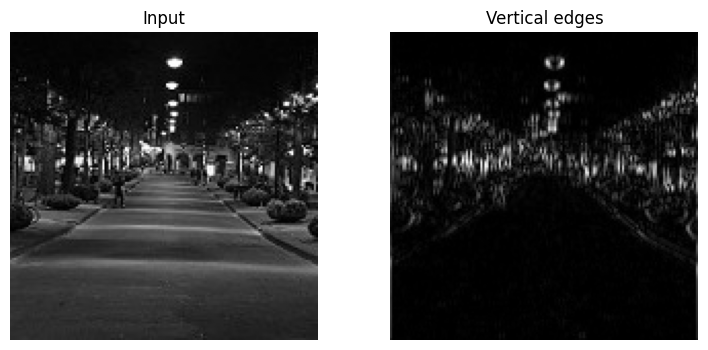

In [3]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())   # expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

In [4]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64   : {count(conv):,} parameters')   # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')   # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64   : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


# Part 2: Convolution and Parameters by Hand

## Task 2.1: reproducing the lecture convolution
The kernel `[-1, 0, 1]` applied to the 5×5 vertical-edge image gave three rows of **[30, 30, 0]**, exactly as in the lecture.
- First output value: (−1×0) + (0×0) + (1×10) = 10 per row, × 3 rows = **30**.
- The last column is **0** because its three pixels are all 10, so there is no left-to-right change.

On the real street photo, the edge map lights up lamp posts, tree trunks and building edges, while flat regions such as the road stay dark. The kernel responds only where brightness changes from left to right.

## Task 2.2: parameter counts
Formula: **parameters = (K × K × C_in + 1) × C_out**

| Layer | Arithmetic | Parameters |
|---|---|---|
| Conv 3×3, 3 → 64 | (3 × 3 × 3 + 1) × 64 = 28 × 64 | **1,792** |
| Dense 67,500 → 512 | 67,500 × 512 + 512 = 34,560,000 + 512 | **34,560,512** |

**The dense layer needs 34,560,512 ÷ 1,792 = 19,286 times more parameters** than the convolution, and both printed values match the formula.

## Output sizes
Formula: **output = (W − K + 2P) / S + 1**

| Operation | Arithmetic | Printed output |
|---|---|---|
| Conv, stride 1 | (224 − 3 + 2)/1 + 1 = 224 | (1, 64, 224, 224) |
| Conv, stride 2 | (224 − 3 + 2)/2 + 1 = 111.5 → 111, then + 1 = 112 | (1, 64, 112, 112) |
| 2×2 max pool | 224 / 2 = 112 | (1, 3, 112, 112) |

Stride 2 halves the width and height, and max pooling does the same while leaving the channel count unchanged.

## Why weight sharing helps
The same small kernel slides over every position, so a feature such as an edge or a texture is detected wherever it appears, and the model learns it once instead of once per location. That is why a convolution can recognise the same object in different parts of an image, and why it needs only 1,792 parameters instead of millions.


In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


# Part 3: Transforms and Data Loaders

## Split sizes
| Split | Images | Transform |
|---|---|---|
| **Train** | **11,929** | RandomResizedCrop(224), horizontal flip, colour jitter, normalise |
| **Validation** | **2,105** | Resize to 224×224, normalise only |
| **Test** | **3,000** | Resize to 224×224, normalise only |

- The 14,034 images in `seg_train` were split 85% / 15%: `int(0.15 × 14,034)` = **2,105** for validation, leaving **11,929** for training.
- The training folder is opened **twice** (one augmented view, one clean view), and both views are split with the **same random indices**. No image appears in both train and validation, and validation images are never augmented.
- Images are resized to 224×224 and normalised with the ImageNet mean and standard deviation, because the pretrained ResNet expects exactly this input.

## Why a validation set when we already have a test set?
Validation accuracy is used to **pick the best epoch** and to **compare feature extraction with fine-tuning**. The test set must play no part in any choice, otherwise its accuracy would no longer be an honest estimate of performance on new images.

## Why augmentation is applied to training data only
Augmentation makes the training images more varied so the model generalises. Validation and test images must stay clean; otherwise their accuracy would measure random distortions rather than the real images.

## A wrong augmentation for each dataset
- **This dataset (scenes): vertical flip.** In real photos the sky is at the top and the ground at the bottom. Upside-down scenes never occur, so the model would learn unrealistic patterns.
- **Handwritten digits: horizontal flip.** A mirrored 2 or 5 is no longer a valid digit, and a large rotation turns a 6 into a 9, so the label becomes wrong.


In [6]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                      # forward pass
            loss = F.cross_entropy(logits, yb)      # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                     # backpropagation
                optimizer.step()                    # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)   # keep the best validation epoch
    return best_acc

In [7]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                           # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))  # new 6-class head
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')

history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (39s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (42s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (38s)
Best validation accuracy, feature extraction: 0.901


# Part 4: The Training Loop and Feature Extraction

## Setup
- **Model:** ResNet-18 pretrained on ImageNet, with **all pretrained layers frozen**.
- **New head:** `nn.Linear(512, 6)`, one output per class.
- **Trainable parameters: 3,078 of 11,179,590** (512 × 6 weights + 6 biases = 3,072 + 6), which is **about 0.028%, or ≈ 0.03%**, of the network.
- **Optimizer:** Adam on the head only, learning rate 1e-3, 3 epochs.
- **The four steps of the training loop:** forward pass → cross-entropy loss → backpropagation (`loss.backward()`) → gradient step (`optimizer.step()`). `fit()` keeps the weights from the best validation epoch.

## Validation accuracy per epoch
| Epoch | Train loss | Train acc | Val loss | **Val acc** |
|---|---|---|---|---|
| 1 | 0.588 | 0.809 | 0.327 | **0.894** |
| 2 | 0.326 | 0.890 | 0.290 | **0.899** |
| 3 | 0.299 | 0.895 | 0.276 | **0.901** |

**Best validation accuracy (feature extraction): 0.901.** Validation accuracy rose every epoch and validation loss fell from 0.327 to 0.276, so the model was still improving and had not started to overfit.

## Why high accuracy is possible while training only 0.03% of the parameters
The frozen ResNet-18 already learned a **feature hierarchy** from 1.2 million ImageNet photos: early layers detect edges and colours, middle layers detect textures and shapes, and deep layers detect object parts. These features are general, so they also describe forests, glaciers and streets. All that remains to learn is how to map the 512 extracted features to our 6 classes, and a single linear layer with 3,078 parameters is enough for that.


In [8]:
for p in model.layer4.parameters():
    p.requires_grad = True                      # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},   # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])      # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.262 acc 0.906 | val loss 0.226 acc 0.926 (40s)
epoch 2: train loss 0.170 acc 0.938 | val loss 0.204 acc 0.931 (38s)
epoch 3: train loss 0.124 acc 0.955 | val loss 0.220 acc 0.927 (39s)
Best validation accuracy, fine-tuned: 0.931


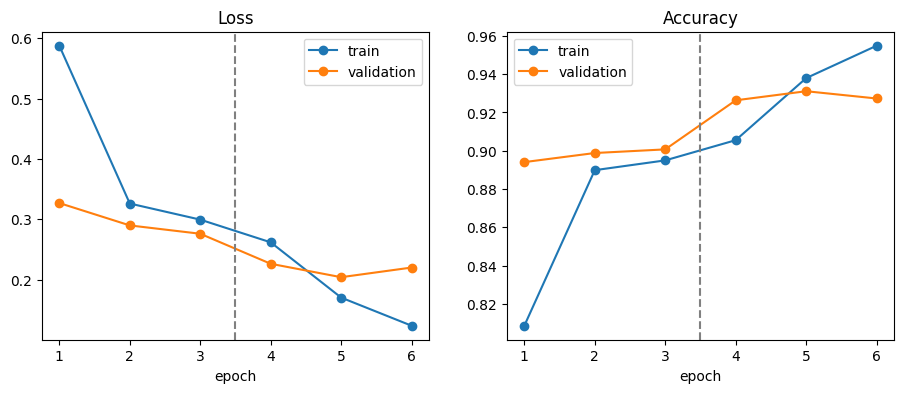

In [9]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')   # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

# Part 5: Fine-Tuning and Learning Curves

## Setup
- **layer4** (the last residual block) was **unfrozen**, so trainable parameters rose from 3,078 to **8,396,806** (about 8.4 million, roughly three quarters of the network).
- **Two learning rates** with Adam: **layer4 = 1e-4** (gentle, so the pretrained weights are adjusted, not destroyed) and the **fc head = 1e-3** (the new head learns faster).
- 3 more epochs, 6 in total.

## Results
| Epoch | Phase | Train loss | Val loss | Train acc | **Val acc** |
|---|---|---|---|---|---|
| 1 | Feature extraction | 0.588 | 0.327 | 0.809 | 0.894 |
| 2 | Feature extraction | 0.326 | 0.290 | 0.890 | 0.899 |
| 3 | Feature extraction | 0.299 | 0.276 | 0.895 | 0.901 |
| 4 | Fine-tuning | 0.262 | 0.226 | 0.906 | 0.926 |
| 5 | Fine-tuning | 0.170 | 0.204 | 0.938 | **0.931** |
| 6 | Fine-tuning | 0.124 | 0.220 | 0.955 | 0.927 |

## Did fine-tuning help?
**Yes.** Best validation accuracy rose from **0.901 to 0.931, a gain of +3.0 percentage points**, and validation loss fell from 0.276 to 0.204. Most of the improvement came right after layer4 was unfrozen (epoch 4: 0.901 → 0.926).

## What the curves show
- **Epochs 1 to 3:** both losses fall steadily.
- **After the dashed line (fine-tuning):** validation loss drops further and reaches its minimum of **0.204 at epoch 5**.
- **Mild overfitting at epoch 6:** training loss keeps falling (0.170 → 0.124) while **validation loss rises** (0.204 → 0.220) and validation accuracy slips (0.931 → 0.927). Training accuracy (0.955) is now clearly above validation accuracy (0.927).
- `fit()` restores the **epoch 5 weights**, so this overfitting does not affect the final model.

## Why training accuracy can be lower than validation accuracy
In epochs 1 to 4, training accuracy (0.809 to 0.906) was **below** validation accuracy (0.894 to 0.926). Training images are **augmented** (random crops, flips, brightness and contrast changes), so they are harder than the clean validation images. Training metrics are also averaged over the whole epoch while the weights are still changing. Once the model fits better (epoch 5 onward), training accuracy overtakes validation accuracy.


Test accuracy: 0.935
              precision    recall  f1-score   support

   buildings      0.952     0.899     0.925       437
      forest      0.994     0.987     0.990       474
     glacier      0.921     0.870     0.895       553
    mountain      0.884     0.918     0.901       525
         sea      0.945     0.982     0.963       510
      street      0.923     0.956     0.939       501

    accuracy                          0.935      3000
   macro avg      0.937     0.935     0.936      3000
weighted avg      0.935     0.935     0.934      3000



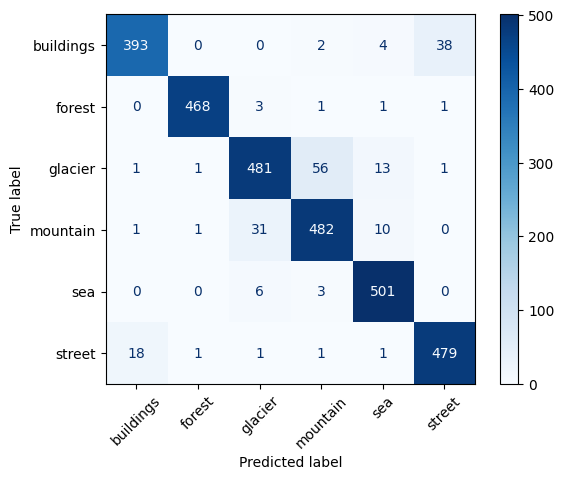

In [10]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

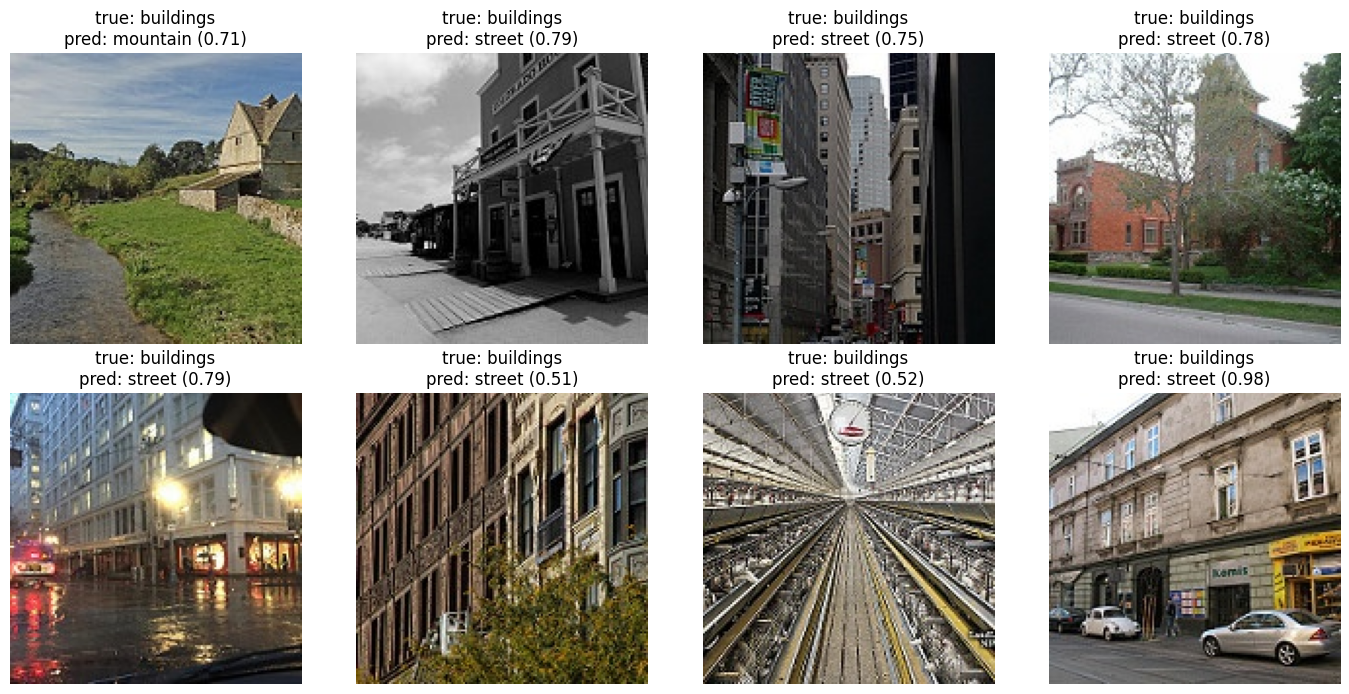

In [11]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

In [12]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit   7.94   probability 1.000
forest     logit  -9.39   probability 0.000
glacier    logit  -4.63   probability 0.000
mountain   logit  -4.99   probability 0.000
sea        logit  -4.61   probability 0.000
street     logit  -3.48   probability 0.000


# Part 6: Test Once, Then Study the Errors

## Test results
The test set was evaluated **once**, using the best validation epoch (epoch 5).

**Test accuracy: 0.935** (2,804 of 3,000 images correct). This is close to the best validation accuracy (0.931), so the model generalises and there is no sign of overfitting to the test set.

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| buildings | 0.952 | **0.899** | 0.925 | 437 |
| forest | 0.994 | 0.987 | 0.990 | 474 |
| glacier | 0.921 | **0.870** | 0.895 | 553 |
| mountain | 0.884 | 0.918 | 0.901 | 525 |
| sea | 0.945 | 0.982 | 0.963 | 510 |
| street | 0.923 | 0.956 | 0.939 | 501 |

- **Two weakest classes by recall: glacier (0.870) and buildings (0.899).**
- **Strongest class:** forest (recall 0.987).

## Which pair is confused most?
From the confusion matrix, **glacier and mountain** are confused most: **56** glacier images were predicted as mountain and **31** mountain images as glacier, **87 errors**, which is 44% of all 196 errors. The second pair is **buildings and street**: 38 buildings predicted as street and 18 street predicted as buildings (56 errors, 29%).

**My Part 1 prediction (glacier vs mountain) was right.** Both classes contain snow, grey rock and blue sky, so their colour and texture features overlap strongly.

## Error gallery: model wrong, label wrong, or image ambiguous?
All 8 gallery errors have true class *buildings*, which fits buildings being a weak class (38 of its 44 errors went to street).
- **Image 1 (buildings → mountain, 0.71): ambiguous image.** A small stone house in a green valley with a stream. The landscape dominates the photo, so the prediction is understandable.
- **Image 7 (buildings → street, 0.52): label questionable.** This looks like a long railway or factory interior, which is neither a building exterior nor a street. The model was unsure (0.52), which fits.
- **Image 8 (buildings → street, 0.98): ambiguous image.** A building row with parked cars, a shop sign and a road is a fair description of a street scene. The model was very confident, but the label is debatable.
- **Image 6 (buildings → street, 0.51): model wrong.** A close-up of a building facade with no road. The model was unsure (0.51), and this is the clearest genuine model mistake.

## Softmax on one image (test image 0, true class: buildings)
The logits ranged from **7.94 (buildings)** down to −9.39 (forest); the runner-up was street at −3.48, a gap of about 11.4. Softmax turned these logits into probabilities that sum to 1: **buildings 1.000**, all others about 0.000. The model was extremely confident, and correct.


In [13]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


# Check Your Understanding

**1. Why does a network without nonlinear activations collapse to a single linear layer?**
Each linear layer is a matrix multiplication, so stacking two gives W₂(W₁x) = (W₂W₁)x. The product W₂W₁ is just **one matrix**, so any number of linear layers is equivalent to one layer and can only learn linear relationships. A nonlinearity such as ReLU between the layers stops them from merging, which is what lets the network learn complex, curved decision boundaries.

**2. For logits [3, 1, 0], what probability does softmax give the first class?**
e³ = 20.086, e¹ = 2.718, e⁰ = 1, so the sum = 23.804.
P(first) = 20.086 / 23.804 = **0.844**

**3. How many parameters in a 3×3 convolution from 64 to 128 channels?**
(K × K × C_in + 1) × C_out = (3 × 3 × 64 + 1) × 128 = 577 × 128 = **73,856**

**4. Output size for a 56×56 input, 3×3 conv, padding 1, stride 2?**
(W − K + 2P)/S + 1 = (56 − 3 + 2)/2 + 1 = 27.5 → 27 (round down), then + 1 = **28**. The output is **28 × 28**.

**5. Why does a residual (skip) connection help gradients reach the early layers?**
A residual block computes y = F(x) + x, so dy/dx = F′(x) + **1**. The "+1" gives the gradient a **direct path** back through the network, so it cannot shrink toward zero even if F′(x) is small. This reduces the vanishing-gradient problem and lets early layers keep learning in very deep networks.

**6. When would you train a CNN from scratch instead of using transfer learning?**
When the images are very different from ImageNet photos (for example spectrograms, radar or other sensor data), so pretrained features do not help; when the input has a different number of channels; or when you have a very large labelled dataset. With a small dataset of ordinary photos, transfer learning is better.
